# code_148 · Native input contracts, context caches and a distilled predictor

**Book:** section 28.5. A self-contained reusable-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Task inputs and helpers are internal. Ordinary execution is offline and CPU-only after the explicit one-time public checkpoint acquisition in the asset guide; local weights are hash-verified, and missing assets fail with instructions. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_28_GUIDE.md), [run evidence](../CHAPTER_28_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_148).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. Task inputs are generated. Named pretrained weights, where used, require the explicitly documented one-time acquisition and immutable hash checks. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3548;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3548


<a id="context-cache-input-contract"></a>
 ## A frozen model still stores task data and computation state
 Use the acquired pinned TabICLv2 classifier; inference is offline. One hundred generated buildings×8records split60source/20development/20final. Numeric inputs contain missing sensor values; material is a string category with missing values. The first16final records introduce an unseen material, with a declared outcome effect. Native TabICL sees the dataframe directly. Context prefixes64/128/256/480 are whole buildings; both cached and uncached modes use one ensemble member and no AMP. Development Brier selects context size; final data never do. Actual fit and three warmed prediction calls are measured in this process. Cache tensor-storage bytes are counted by unique storage, while post-fit RSS is only a process-state observation, not peak model memory. A separate histogram student learns teacher probabilities on480source features plus1,520fresh unlabelled generated features; real labels from the latter are discarded and never fit it.


,context_records,cached,development_Brier,context_prevalence,cache_tensor_storage_bytes
0,64,False,0.234795,0.515625,0
1,64,True,0.234795,0.515625,6291456
2,128,False,0.223754,0.460938,0
3,128,True,0.223754,0.460938,9437184
4,256,False,0.214804,0.476562,0
5,256,True,0.214804,0.476562,15728640
6,480,False,0.223737,0.429167,0
7,480,True,0.223737,0.429167,26738688


,model,final_Brier,final_records
0,Frozen native teacher,0.206978,160
1,Distilled histogram student,0.206792,160
2,Source-label histogram,0.211125,160


Resource observations: {'observations': [{'context_records': 64, 'cached': False, 'fit_seconds_including_local_load': 0.09244808299990837, 'warm_prediction_median_seconds': 0.04383470900938846, 'post_fit_process_RSS_bytes': 880508928}, {'context_records': 64, 'cached': True, 'fit_seconds_including_local_load': 0.10233504200004973, 'warm_prediction_median_seconds': 0.027104416003567167, 'post_fit_process_RSS_bytes': 997015552}, {'context_records': 128, 'cached': False, 'fit_seconds_including_local_load': 0.08072054199874401, 'warm_prediction_median_seconds': 0.05577654100488871, 'post_fit_process_RSS_bytes': 1114980352}, {'context_records': 128, 'cached': True, 'fit_seconds_including_local_load': 0.11410950000572484, 'warm_prediction_median_seconds': 0.027626959010376595, 'post_fit_process_RSS_bytes': 1229357056}, {'context_records': 256, 'cached': False, 'fit_seconds_including_local_load': 0.09802291600499302, 'warm_prediction_median_seconds': 0.08032599999569356, 'post_fit_process_RSS

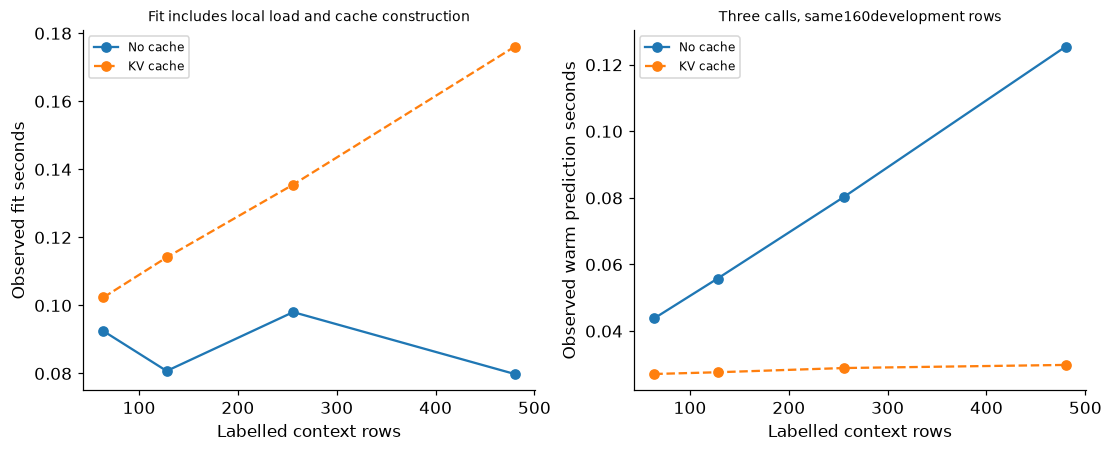

In [2]:
import os,hashlib,importlib.metadata as metadata,psutil
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1'
from tabicl import TabICLClassifier
from sklearn.ensemble import HistGradientBoostingClassifier,HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import make_pipeline
VERSIONS['tabicl']=metadata.version('tabicl');VERSIONS['psutil']=metadata.version('psutil');ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (p/'examples.json').is_file());revision='4dcd344ece2c00be9e831fdd35bed57b5ad83e19';filename='tabicl-classifier-v2-20260212.ckpt';checkpoint=ROOT/'build/model-cache/models--jingang--TabICL/snapshots'/revision/filename;digest='bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0';assert checkpoint.is_file(),'Run python scripts/acquire_chapter28_models.py';assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==digest
materials=np.array(['concrete','steel','timber'],dtype=object)
def cohort(n,unseen=0):
    latent=rng.normal(size=(n,3));mat=rng.choice(materials,n);effect=np.array([{'concrete':0.,'steel':.4,'timber':-.3}[v] for v in mat]);mat[:unseen]='composite';effect[:unseen]=.8;building_effect=np.repeat(rng.normal(0,.3,n//8),8);label=rng.binomial(1,1/(1+np.exp(-(-.7+.8*latent[:,0]-.6*latent[:,1]+.3*latent[:,2]**2+effect+building_effect))));frame=pd.DataFrame(latent,columns=['load','sensor','age_summary']);frame['material']=mat;frame.loc[rng.uniform(size=n)<.15,'sensor']=np.nan;frame.loc[rng.uniform(size=n)<.08,'material']=None;return frame,label
# Source/development and final whole-building cohorts are drawn separately once.
frame,y=cohort(640)
final_frame,final_y=cohort(160,16);source_frame=frame.iloc[:480].copy();source_y=y[:480];dev_frame=frame.iloc[480:640].copy();dev_y=y[480:640];context_sizes=[64,128,256,480];fit_rows=[];profiles=[];models={};cache_differences=[];cache_sizes=[]
def storage_bytes(obj):
    visited=set();storages=set()
    def walk(value):
        if id(value) in visited:return 0
        visited.add(id(value))
        if isinstance(value,torch.Tensor):
            storage=value.untyped_storage();key=(storage.data_ptr(),storage.nbytes());fresh=key not in storages;storages.add(key);return storage.nbytes() if fresh else 0
        if isinstance(value,dict):return sum(walk(v) for v in value.values())
        if isinstance(value,(list,tuple)):return sum(walk(v) for v in value)
        if hasattr(value,'__dict__'):return sum(walk(v) for v in vars(value).values())
        return 0
    return walk(obj)
for size in context_sizes:
    predictions=[]
    for cached in [False,True]:
        model=TabICLClassifier(n_estimators=1,kv_cache=cached,model_path=checkpoint,allow_auto_download=False,device='cpu',use_amp=False,use_fa3=False,n_jobs=1,random_state=SEED);begin=time.perf_counter();model.fit(source_frame.iloc[:size],source_y[:size]);fit_seconds=time.perf_counter()-begin;rss=psutil.Process().memory_info().rss;model.predict_proba(dev_frame);times=[]
        for repeat in range(3):begin=time.perf_counter();p=model.predict_proba(dev_frame)[:,1];times.append(time.perf_counter()-begin)
        score=float(np.mean((p-dev_y)**2));cache=getattr(model,'model_kv_cache_',None);cache_bytes=storage_bytes(cache);fit_rows.append({'context_records':size,'cached':cached,'development_Brier':score,'context_prevalence':float(source_y[:size].mean()),'cache_tensor_storage_bytes':cache_bytes});profiles.append({'context_records':size,'cached':cached,'fit_seconds_including_local_load':fit_seconds,'warm_prediction_median_seconds':float(np.median(times)),'post_fit_process_RSS_bytes':rss});predictions.append(p);models[(size,cached)]=model
        assert (cache_bytes>0)==cached
    difference=float(np.max(np.abs(predictions[0]-predictions[1])));np.testing.assert_allclose(predictions[0],predictions[1],atol=2e-5,rtol=2e-5);cache_differences.append(difference);cache_sizes.append(fit_rows[-1]['cache_tensor_storage_bytes'])
chosen=min([r for r in fit_rows if r['cached']],key=lambda row:row['development_Brier']);teacher=models[(chosen['context_records'],True)];teacher_probability=teacher.predict_proba(final_frame)[:,1];unlabelled,_discarded=cohort(1520);distill_frame=pd.concat([source_frame,unlabelled],ignore_index=True);soft_target=teacher.predict_proba(distill_frame)[:,1]
def preprocessing():return ColumnTransformer([('numeric','passthrough',['load','sensor','age_summary']),('material',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=np.nan,encoded_missing_value=np.nan),['material'])],verbose_feature_names_out=False)
student_rows=[];best=np.inf
for leaves in [7,15]:
    student=make_pipeline(preprocessing(),HistGradientBoostingRegressor(max_iter=100,learning_rate=.05,max_leaf_nodes=leaves,min_samples_leaf=15,l2_regularization=1,categorical_features=[3],early_stopping=False,random_state=SEED)).fit(distill_frame,soft_target);p=student.predict(dev_frame).clip(0,1);score=float(np.mean((p-dev_y)**2));student_rows.append({'leaves':leaves,'development_Brier':score})
    if score<best:best=score;selected_student=student;selected_leaves=leaves
baseline=make_pipeline(preprocessing(),HistGradientBoostingClassifier(max_iter=100,learning_rate=.05,max_leaf_nodes=7,min_samples_leaf=15,l2_regularization=1,categorical_features=[3],early_stopping=False,random_state=SEED)).fit(source_frame,source_y);student_probability=selected_student.predict(final_frame).clip(0,1);base_probability=baseline.predict_proba(final_frame)[:,1];assessment=[{'model':name,'final_Brier':float(np.mean((p-final_y)**2)),'final_records':160} for name,p in [('Frozen native teacher',teacher_probability),('Distilled histogram student',student_probability),('Source-label histogram',base_probability)]];student_disagreement=float(np.mean((student_probability-teacher_probability)**2));assert np.all(np.isfinite(teacher_probability)) and np.all(np.isfinite(student_probability))
resource_profile={'observations':profiles,'measurement':'One CPU process; each fresh wrapper fit includes local checkpoint load; median of three warmed same160-row predictions. RSS is process state after fit, not a peak or isolated model allocation. Cache storage counts unique Torch storages.'}
RESULTS.update(building_counts=[60,20,20],record_counts=[480,160,160],context_comparisons=fit_rows,selected_context_records=chosen['context_records'],cache_uncached_max_probability_differences=cache_differences,cache_storage_bytes_by_context=cache_sizes,student_candidates=student_rows,selected_student_leaves=selected_leaves,distillation_feature_records=2000,distillation_fit_real_labels_used=0,student_selection_real_labels=160,teacher_source_context_labels=chosen['context_records'],student_teacher_final_probability_MSE=student_disagreement,assessments=assessment,source_numeric_missing_records=int(source_frame.sensor.isna().sum()),source_categorical_missing_records=int(source_frame.material.isna().sum()),final_unseen_category_records=int((final_frame.material=='composite').sum()),checkpoint_sha256=digest);display(pd.DataFrame(fit_rows));display(pd.DataFrame(assessment));print('Resource observations:',resource_profile)
# RESOURCE_OBSERVATION_FOR_FIGURE: book reproduction reuses this run's captured timings after executing all computations and numerical assertions.
fig,axes=plt.subplots(1,2,figsize=(10,4))
for cached,style in [(False,'-'),(True,'--')]:
    rr=[r for r in resource_profile['observations'] if r['cached']==cached];axes[0].plot(context_sizes,[r['fit_seconds_including_local_load'] for r in rr],style+'o',label='KV cache' if cached else 'No cache');axes[1].plot(context_sizes,[r['warm_prediction_median_seconds'] for r in rr],style+'o',label='KV cache' if cached else 'No cache')
axes[0].set(xlabel='Labelled context rows',ylabel='Observed fit seconds',title='Fit includes local load and cache construction');axes[1].set(xlabel='Labelled context rows',ylabel='Observed warm prediction seconds',title='Three calls, same160development rows');axes[0].legend(fontsize=8);axes[1].legend(fontsize=8);plt.show()


<a id="cache-and-distillation-limits"></a>
 ## Cached inference and a student change different parts of the workflow
 KV caching retains context computation while preserving the native predictor up to the checked float32 tolerance. Measured unique cache storage differs from operating-system RSS, which includes this shared process, multiple wrappers and allocator history. Timings are observations, not portable throughput promises. The histogram student fits parameters to teacher probabilities onsource/input-only generated features; those extra labels are predictions rather than independent observed outcomes. Two fixed student leaf counts select with real development outcomes. Final160records select neither context nor student. Source-labelled histogram controls receive480labels, while a selected smaller teacher context may receive fewer; counts remain explicit. Native string/missing/unknown-category handling is tested rather than universally replaced with one-hot encoding. This lab executes context conditioning, caching and distillation; it does not call native fine-tuning or claim that the unchanged weights of an in-context wrapper were optimized.


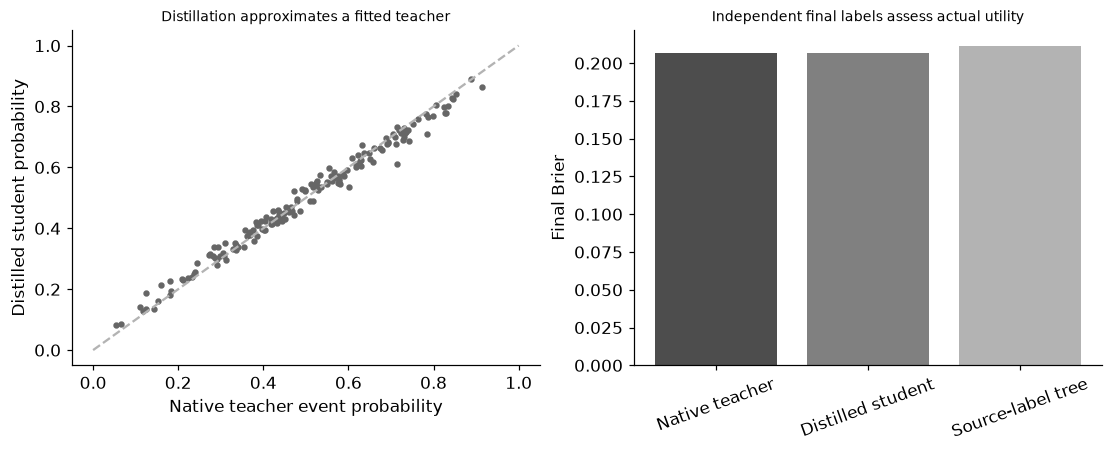

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(teacher_probability,student_probability,s=10,color='.4');axes[0].plot([0,1],[0,1],'--',color='.7');axes[0].set(xlabel='Native teacher event probability',ylabel='Distilled student probability',title='Distillation approximates a fitted teacher');axes[1].bar(['Native teacher','Distilled student','Source-label tree'],[r['final_Brier'] for r in assessment],color=['.3','.5','.7']);axes[1].set(ylabel='Final Brier',title='Independent final labels assess actual utility');axes[1].tick_params(axis='x',labelrotation=20);plt.show()
assert len(assessment)==3 and all(np.isfinite(r['final_Brier']) for r in assessment)


In [4]:
summary={'example_id':'code_148','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual native mixed-type and missing-value handling', 'labelled-context size selection', 'native KV-cache numerical and storage audit', 'measured CPU fit and repeat-prediction observations', 'actual teacher-probability distillation with held-out evaluation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual native mixed-type and missing-value handling", "labelled-context size selection", "native KV-cache numerical and storage audit", "measured CPU fit and repeat-prediction observations", "actual teacher-probability distillation with held-out evaluation"], "elapsed_seconds": 4.155, "example_id": "code_148", "hardware": "Darwin arm64 CPU", "resource_observations": {"measurement": "One CPU process; each fresh wrapper fit includes local checkpoint load; median of three warmed same160-row predictions. RSS is process state after fit, not a peak or isolated model allocation. Cache storage counts unique Torch storages.", "observations": [{"cached": false, "context_records": 64, "fit_seconds_including_local_load": 0.09244808299990837, "post_fit_process_RSS_bytes": 880508928, "warm_prediction_median_seconds": 0.04383470900938846}, {"cached": true, "context_records": 64, "fit_seconds_including_local_load": 0.10233504200004973, "post_fit_proce